Import packages

In [1]:
import matplotlib.pyplot as plt
import numpy as np

Defining function for converting txt to array of 1's and 0's.

In [8]:
def readtxt(file):
    grid = []
    with open(file, "r") as fil:
        lines = fil.readlines()
    for line in lines:
        #checking whether it even is a line
        if line:
            lin = []
            for i in line:
                if i=="#":
                    i = 1
                else:
                    i=0
                
                lin.append(i)
            grid.append(lin)
    return np.array(grid)

Defining function to check for active neighbors (1's)

In [9]:
def GudSoil(grid,x,y):
    act=0
    #I get the dimensions of the grid, to see if what I'm checking for is there
    rowlen, collen = grid.shape
    #I check in a 3x3 around the chosen coordinate in the grid, with the exception of the coordinate itself
    for i in range(x-1,x+2):
        for j in range(y-1,y+2):
            if (i,j) != (x,y):
                if 0<=i<rowlen and 0<=j<collen:
                    if grid[i,j] == 1:
                        act+=1

    return act
                

Define code for how next grid in time looks. 

In [13]:
def nextgrid(grid):
    rowlen, collen = grid.shape
    #I make temporary copy of grid, so original doesn't change. that way, i can stil make use of old grid
    gridtemp = grid.copy()

    for i in range(rowlen):
        for j in range(collen):
            actpeeps = GudSoil(grid,i,j)
            #I define rules
            if grid[i,j] == 1:
                if actpeeps == 3 or actpeeps == 2:
                    gridtemp[i,j] = 1
                else:
                    gridtemp[i,j] = 0
            else:
                if actpeeps == 3:
                    gridtemp[i,j] = 1
    return gridtemp

I define a function to print every grid per time.

In [6]:
def printgrid(grid, tim):
    print(f"Time:{tim}")
    for row in grid:
        print(*row, sep="")

Defining simulation function

In [24]:
def sim(file, steps):
    grid = readtxt(file)
    print(f"Simulation: {file}")
    printgrid(grid,0)
    #Defining list for number of active cells
    acttotal =[np.sum(grid)]

    for t in range(1, steps+1):
        grid = nextgrid(grid)
        acttotal.append(np.sum(grid))

        if t in [1,2,4,6,10,16]:
            printgrid(grid,t)

    return acttotal


In [25]:
Data = ["blinker.txt","glider.txt","pentomino.txt"]
results ={}
steps = 16
for file in Data:
    results[file] = sim(file, steps)

Simulation: blinker.txt
Time:0
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000001110000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
Time:1
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000000100000000
000000100000000
000000100000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
Time:2
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000001110000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
Time:4
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000001110000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
000000000000000
Time:6
000000000000000
000000000000000
0000000000000

Now plotting total number of active sites

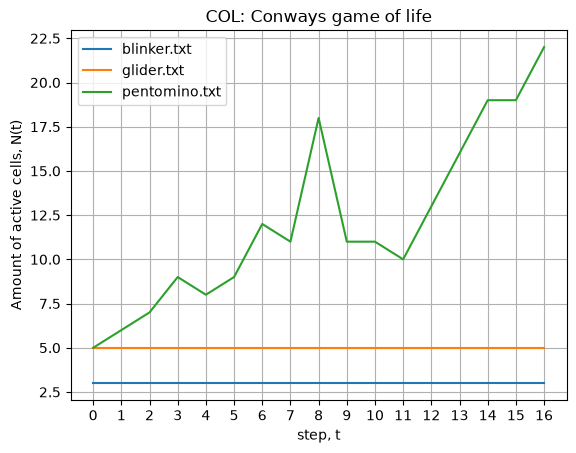

In [ ]:
for file,counts in results.items():
    tim= np.arange(steps+1)
    plt.plot(tim, counts,label=file)
plt.xlabel("step, t")
plt.ylabel("Amount of active cells, N(t)")
plt.title("COL: Conways game of life")
plt.xticks(range(steps+1))
plt.grid(True)
plt.legend()
plt.savefig("activePeeps.png",dpi=300)
plt.show()